<a href="https://colab.research.google.com/github/denisgabdukaev/-.-/blob/main/AI_BigData_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys

# Install dependencies if the notebook is running in Colab
if 'google.colab' in sys.modules:
    !pip install -U -qq tsa-course

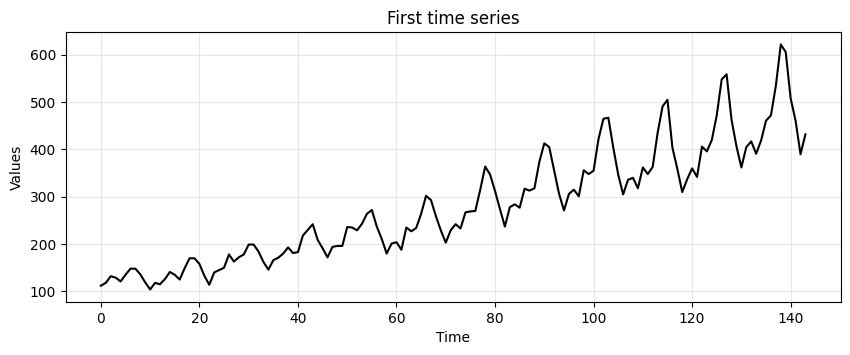

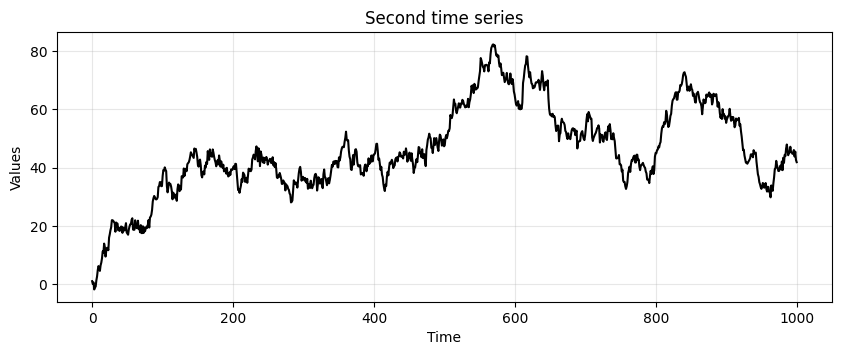

smoothing_ts1: MSE = 6402.7300
smoothing_ts2: MSE = 5.3141


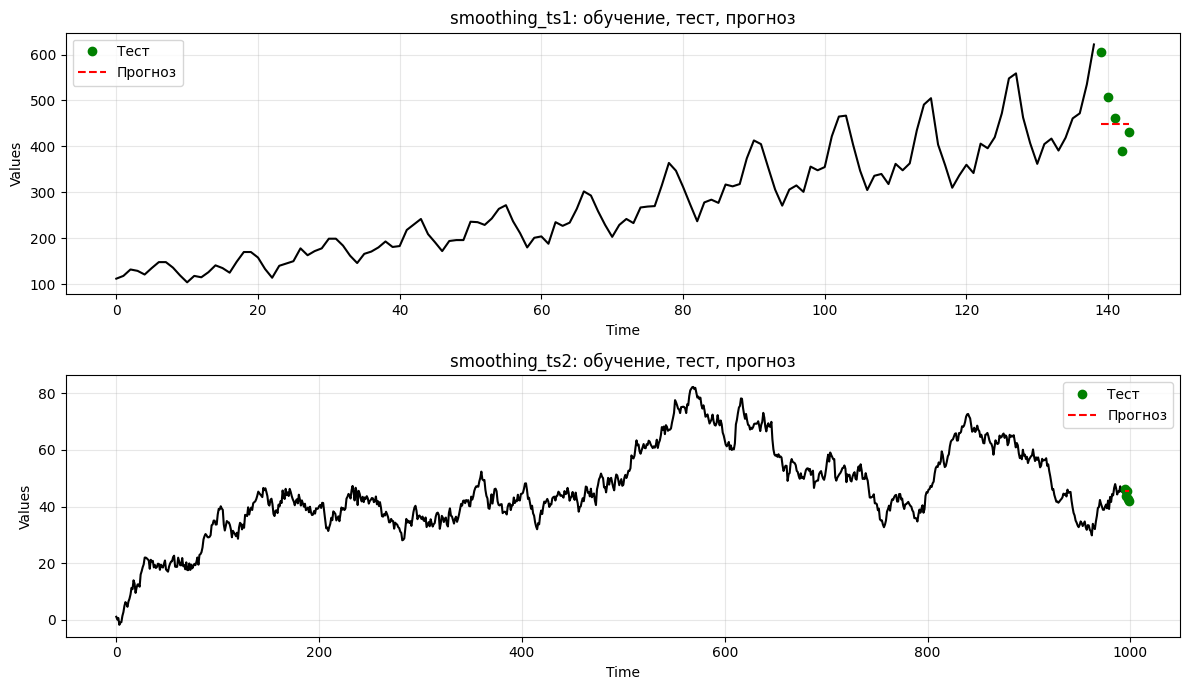

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import BytesIO
from statsmodels.tsa.seasonal import seasonal_decompose

# Функция построения графика последовательности запусков
def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(10, 3.5))
    ax.plot(x, y, 'k-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax


# Загрузка данных
response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts1.npy?download=1")
response.raise_for_status()
smoothing_ts1 = np.load(BytesIO(response.content))

response = requests.get("https://zenodo.org/records/10897398/files/smoothing_ts4_4.npy?download=1")
response.raise_for_status()
smoothing_ts2 = np.load(BytesIO(response.content))

# Временные переменные
mytime1 = np.arange(len(smoothing_ts1))
mytime2 = np.arange(len(smoothing_ts2))

# Графики исходных рядов
run_sequence_plot(mytime1, smoothing_ts1, title="First time series")
run_sequence_plot(mytime2, smoothing_ts2, title="Second time series")

plt.show()


# Функция сглаживания и прогноза
def smooth_and_forecast(series, n_test=5, window=10):
    train = series[:-n_test]
    test = series[-n_test:]
    smoothed_train = np.convolve(train, np.ones(window) / window, mode='valid')
    forecast = np.full(n_test, smoothed_train[-1])
    return train, test, smoothed_train, forecast


def mse(actual, predicted):
    return np.mean((np.asarray(actual) - np.asarray(predicted)) ** 2)


# Разделение, сглаживание и прогноз
n_test = 5
window = 10

train1, test1, smoothed1, forecast1 = smooth_and_forecast(smoothing_ts1, n_test, window)
train2, test2, smoothed2, forecast2 = smooth_and_forecast(smoothing_ts2, n_test, window)

print(f"smoothing_ts1: MSE = {mse(test1, forecast1):.4f}")
print(f"smoothing_ts2: MSE = {mse(test2, forecast2):.4f}")


# Графики: обучение, тест и прогноз
t_train1 = np.arange(len(train1))
t_test1 = np.arange(len(train1), len(train1) + n_test)

t_train2 = np.arange(len(train2))
t_test2 = np.arange(len(train2), len(train2) + n_test)

fig, axes = plt.subplots(2, 1, figsize=(12, 7))

run_sequence_plot(t_train1, train1, title="smoothing_ts1: обучение, тест, прогноз", ax=axes[0])
axes[0].plot(t_test1, test1, 'go', label='Тест')
axes[0].plot(t_test1, forecast1, 'r--', label='Прогноз')
axes[0].legend()

run_sequence_plot(t_train2, train2, title="smoothing_ts2: обучение, тест, прогноз", ax=axes[1])
axes[1].plot(t_test2, test2, 'go', label='Тест')
axes[1].plot(t_test2, forecast2, 'r--', label='Прогноз')
axes[1].legend()

plt.tight_layout()
plt.show()